In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family": ["Calibri", "DejaVu Sans"], "font.size": 12,
                     "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
RED, BLUE, GREY = "#C0392B", "#2E86AB", "#95A5A6"

users  = pd.read_csv("../data/clean/user_clean.csv", parse_dates=["signup_date"])
status = pd.read_csv("../data/clean/status_clean.csv")
feat   = pd.read_csv("../data/clean/user_features.csv", index_col="user_id")
d = users.merge(status[["user_id", "is_churn"]], on="user_id")
avg = d.is_churn.mean() * 100

# ---------- Grafik 0: churn rate per channel & per cohort (hasil SQL Part 1) -> ukuran tempel 12.3 x 3.4 inci ----------
ch = d.groupby("acquisition_channel").is_churn.agg(["size", "mean"]).sort_values("mean", ascending=False)
co = d.groupby(d.signup_date.dt.to_period("M")).is_churn.agg(["size", "mean"])
fig, axs = plt.subplots(1, 2, figsize=(12.3, 3.4), gridspec_kw={"width_ratios": [1, 1.6]}, sharey=True)
b = axs[0].bar([f"{c}\n(n={n})" for c, n in zip(ch.index, ch["size"])], ch["mean"] * 100, color=GREY, width=0.6)
for bar, v in zip(b, ch["mean"] * 100):
    axs[0].text(bar.get_x() + bar.get_width() / 2, v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=14)
axs[0].set_title("Per channel akuisisi"); axs[0].set_ylabel("Churn rate (%)")
b = axs[1].bar([f"{m}\n(n={n})" for m, n in zip(co.index.strftime("%b"), co["size"])], co["mean"] * 100, color=GREY, width=0.6)
for bar, v in zip(b, co["mean"] * 100):
    axs[1].text(bar.get_x() + bar.get_width() / 2, v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=13)
axs[1].set_title("Per cohort bulan signup (2024)")
for ax in axs: ax.axhline(avg, ls="--", c="black", lw=1); ax.set_ylim(0, 50)
axs[0].text(1.5, avg + 1.2, f"Rata-rata {avg:.0f}%", fontsize=11)
plt.tight_layout(); plt.savefig("charts/0_channel_cohort.png", dpi=200); plt.close()

# ---------- Grafik 5a: churn rate per segmen -> ukuran tempel 6 x 3.8 inci ----------
feat["segmen"] = np.where(feat.n_trx == 1, "High risk\n(1 pinjaman)", "Low risk\n(2+ pinjaman)")
s = feat.groupby("segmen").is_churn.agg(["size", "sum", "mean"]).loc[["High risk\n(1 pinjaman)", "Low risk\n(2+ pinjaman)"]]
fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.bar(s.index, s["mean"] * 100, color=[RED, BLUE], width=0.5)
for bar, (n, k, v) in zip(bars, zip(s["size"], s["sum"], s["mean"] * 100)):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 1.5, f"{v:.0f}%", ha="center", fontweight="bold", fontsize=14)
    ax.text(bar.get_x() + bar.get_width() / 2, min(v / 2, 15), f"{int(k)} churn\ndari {int(n)} user", ha="center", va="center", color="white", fontweight="bold")
ax.axhline(avg, ls="--", c="black", lw=1); ax.text(0.5, avg + 1.5, f"Rata-rata {avg:.0f}%", ha="center", fontsize=11)
ax.set_ylim(0, 85); ax.set_ylabel("Churn rate (%)"); ax.set_title("Churn rate per segmen risiko")
plt.tight_layout(); plt.savefig("charts/5a_segmen.png", dpi=200); plt.close()

# ---------- Strip KPI untuk slide 1 -> ukuran tempel 12.3 x 1.6 inci ----------
kpi = [("29,6%", "churn rate keseluruhan\n(74 dari 250 user)", RED),
       ("69%", "churn pada user yang baru\n1 kali meminjam", RED),
       ("36%", "churner berasal dari hanya\n16% user (high-risk)", RED),
       ("2,3x", "lebih efisien menarget segmen\nhigh-risk vs semua user", BLUE)]
fig, axs = plt.subplots(1, 4, figsize=(12.3, 1.6))
for ax, (big, small, col) in zip(axs, kpi):
    ax.axis("off"); ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color="#F4F6F7"))
    ax.add_patch(plt.Rectangle((0, 0), 0.025, 1, transform=ax.transAxes, color=col))
    ax.text(0.09, 0.62, big, fontsize=30, fontweight="bold", color=col, va="center", transform=ax.transAxes)
    ax.text(0.09, 0.17, small, fontsize=11, color="#2C3E50", va="center", transform=ax.transAxes)
fig.subplots_adjust(left=0.003, right=0.997, top=0.97, bottom=0.03, wspace=0.04)
plt.savefig("charts/kpi_strip.png", dpi=200); plt.close()

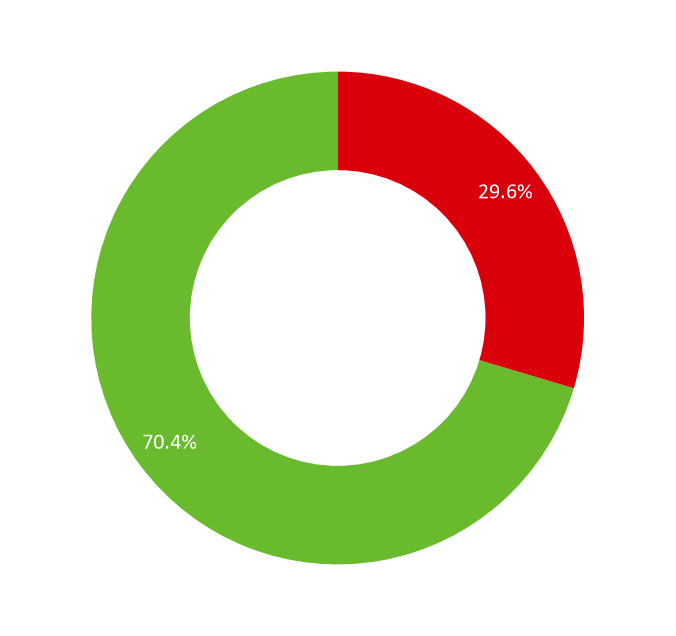

In [17]:
# Visualization support for sql question 1 (active vs churn users) & churn rates

# data
counts = feat['is_churn'].value_counts(normalize=True)
labels = ["Active Users", "Churn Users"]
colors = ['#69ba2d', '#d9000c']

# Pie chart
fig, ax = plt.subplots(figsize=(8,8))
wedges, texts, autotexts = ax.pie(counts, labels=labels, colors=colors,
                                  autopct='%1.1f%%', startangle=90, pctdistance=0.85,
                                  textprops={'color': 'white', 'fontsize': 16})

# Donut hole
centre_circle = plt.Circle((0,0),0.60,fc='white')
fig.gca().add_artist(centre_circle)

plt.show()